In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay
)

In [14]:
df = pd.read_csv('WineQT.csv')

print(df.head())
print('\nDataset Shape:', df.shape)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

In [15]:
print('Dataset Information:')
df.info()

print('\nMissing Values:')
print(df.isnull().sum())

print('\nQuality Score Counts:')
print(df['quality'].value_counts().sort_index())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB

Missing Values:
fixed acidity           0
volatile ac

In [16]:
df['quality_class'] = (df['quality'] >= 7).astype(int)

print('Class Distribution:')
print(df['quality_class'].value_counts().rename(index={0: 'Not Good (0)', 1: 'Good (1)'}))

print('\nClass Percentages:')
print((df['quality_class'].value_counts(normalize=True) * 100).round(2))

Class Distribution:
quality_class
Not Good (0)    984
Good (1)        159
Name: count, dtype: int64

Class Percentages:
quality_class
0    86.09
1    13.91
Name: proportion, dtype: float64


In [17]:
X = df.drop(columns=['quality', 'quality_class', 'Id'])
y = df['quality_class']

print('Independent variables shape:', X.shape)
print('Dependent variable shape:', y.shape)

Independent variables shape: (1143, 11)
Dependent variable shape: (1143,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)

print('\nTraining class distribution:')
print(y_train.value_counts())
print('\nTesting class distribution:')
print(y_test.value_counts())

Training data: (914, 11)
Testing data: (229, 11)

Training class distribution:
quality_class
0    787
1    127
Name: count, dtype: int64

Testing class distribution:
quality_class
0    197
1     32
Name: count, dtype: int64


In [19]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(class_weight='balanced', max_iter=1000))
])

model.fit(X_train, y_train)

print('Logistic Regression model trained successfully.')

Logistic Regression model trained successfully.


In [20]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print('First 10 predicted classes:')
print(y_pred[:10])

print('\nClass labels: 0 = Not Good, 1 = Good')

First 10 predicted classes:
[1 1 0 0 0 0 1 0 1 0]

Class labels: 0 = Not Good, 1 = Good


In [21]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print('Accuracy:', accuracy)
print('Precision:', precision)
print('Recall:', recall)
print('F1 Score:', f1)
print('ROC-AUC Score:', roc_auc)

print('\nClassification Report:')
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=['Not Good', 'Good'],
    zero_division=0
))

Accuracy: 0.7991266375545851
Precision: 0.3793103448275862
Recall: 0.6875
F1 Score: 0.4888888888888889
ROC-AUC Score: 0.8504124365482234

Classification Report:
              precision    recall  f1-score   support

    Not Good       0.94      0.82      0.88       197
        Good       0.38      0.69      0.49        32

    accuracy                           0.80       229
   macro avg       0.66      0.75      0.68       229
weighted avg       0.86      0.80      0.82       229



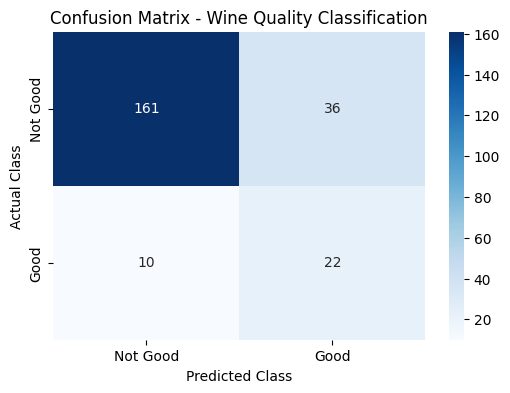

In [22]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Not Good', 'Good'],
    yticklabels=['Not Good', 'Good']
)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix - Wine Quality Classification')
plt.show()

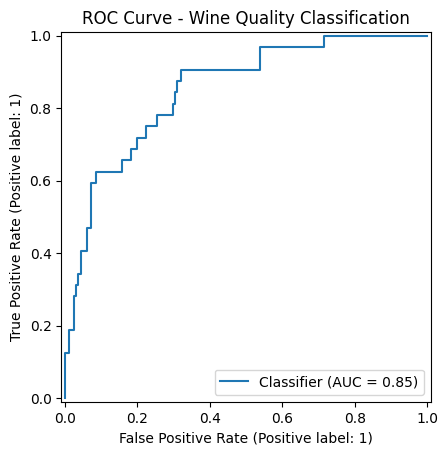

In [23]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title('ROC Curve - Wine Quality Classification')
plt.show()

In [24]:
result = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred,
    'Probability of Good': y_probability
})

result['Actual Class'] = result['Actual Class'].map({0: 'Not Good', 1: 'Good'})
result['Predicted Class'] = result['Predicted Class'].map({0: 'Not Good', 1: 'Good'})

display(result.head(10))

,Actual Class,Predicted Class,Probability of Good
0,Not Good,Good,0.806196
1,Not Good,Good,0.913572
2,Good,Not Good,0.293476
3,Not Good,Not Good,0.233401
4,Not Good,Not Good,0.222653
5,Not Good,Not Good,0.094517
6,Not Good,Good,0.914538
7,Not Good,Not Good,0.159024
8,Not Good,Good,0.937020
9,Not Good,Not Good,0.014229
